In [45]:
# DATA LOADING

In [16]:
import pandas as pd #import pandas as pd memanggil library pandas dengan nama singkat pd.
import numpy as np #import numpy as np memanggil NumPy untuk operasi numerik.
import matplotlib.pyplot as plt #import matplotlib.pyplot as plt digunakan untuk membuat grafik.
import seaborn as sns #import seaborn as sns digunakan untuk membuat grafik statistik.

In [17]:
df = pd.read_csv("laptops.csv") #pd.read_csv() adalah fungsi untuk membaca file CSV. "laptops.csv" adalah nama file yang ingin dibaca. df adalah variabel yang menyimpan data dalam bentuk DataFrame.

In [18]:
df.head() #Fungsi head() menampilkan lima baris pertama secara default.

,Laptop,Status,Brand,Model,CPU,RAM,Storage,Storage type,GPU,Screen,Touch,Final Price
0,ASUS ExpertBook B1 B1502CBA-EJ0436X Intel Core...,New,Asus,ExpertBook,Intel Core i5,8,512,SSD,NaN,15.6,No,1009.00
1,Alurin Go Start Intel Celeron N4020/8GB/256GB ...,New,Alurin,Go,Intel Celeron,8,256,SSD,NaN,15.6,No,299.00
2,ASUS ExpertBook B1 B1502CBA-EJ0424X Intel Core...,New,Asus,ExpertBook,Intel Core i3,8,256,SSD,NaN,15.6,No,789.00
3,MSI Katana GF66 12UC-082XES Intel Core i7-1270...,New,MSI,Katana,Intel Core i7,16,1000,SSD,RTX 3050,15.6,No,1199.00
4,HP 15S-FQ5085NS Intel Core i5-1235U/16GB/512GB...,New,HP,15S,Intel Core i5,16,512,SSD,NaN,15.6,No,669.01


In [19]:
print("Jumlah baris dan kolom:", df.shape) #Fungsi shape mengembalikan dua angka: jumlah baris dan jumlah kolom.

Jumlah baris dan kolom: (2160, 12)


In [20]:
df.info() #Fungsi info() menampilkan: Nama setiap kolom. Jumlah nilai yang tidak kosong. Tipe data. Penggunaan memori.

<class 'pandas.DataFrame'>
RangeIndex: 2160 entries, 0 to 2159
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Laptop        2160 non-null   str    
 1   Status        2160 non-null   str    
 2   Brand         2160 non-null   str    
 3   Model         2160 non-null   str    
 4   CPU           2160 non-null   str    
 5   RAM           2160 non-null   int64  
 6   Storage       2160 non-null   int64  
 7   Storage type  2118 non-null   str    
 8   GPU           789 non-null    str    
 9   Screen        2156 non-null   float64
 10  Touch         2160 non-null   str    
 11  Final Price   2160 non-null   float64
dtypes: float64(2), int64(2), str(8)
memory usage: 202.6 KB


In [21]:
df.describe() #Fungsi describe() memberikan ringkasan statistik untuk kolom numerik, seperti jumlah data, rata-rata, standar deviasi, nilai minimum, kuartil, dan maksimum.

,RAM,Storage,Screen,Final Price
count,2160.000000,2160.000000,2156.000000,2160.000000
mean,15.413889,596.294444,15.168112,1312.638509
std,9.867815,361.220506,1.203329,911.475417
min,4.000000,0.000000,10.100000,201.050000
25%,8.000000,256.000000,14.000000,661.082500
50%,16.000000,512.000000,15.600000,1031.945000
75%,16.000000,1000.000000,15.600000,1708.970000
max,128.000000,4000.000000,18.000000,7150.470000


In [22]:
# DATA CLEANING

In [23]:
df.isnull().sum() #isnull() memeriksa apakah nilai pada setiap sel kosong. sum() menghitung jumlah nilai kosong pada setiap kolom.

Laptop             0
Status             0
Brand              0
Model              0
CPU                0
RAM                0
Storage            0
Storage type      42
GPU             1371
Screen             4
Touch              0
Final Price        0
dtype: int64

In [24]:
print("Jumlah data duplikat:", df.duplicated().sum()) #Fungsi duplicated() memeriksa apakah terdapat baris yang isinya identik dengan baris sebelumnya.

Jumlah data duplikat: 0


In [25]:
df.dtypes #Memeriksa tipe data

Laptop              str
Status              str
Brand               str
Model               str
CPU                 str
RAM               int64
Storage           int64
Storage type        str
GPU                 str
Screen          float64
Touch               str
Final Price     float64
dtype: object

In [26]:
# Memeriksa jumlah data kosong di setiap kolom
print(df.isnull().sum())

Laptop             0
Status             0
Brand              0
Model              0
CPU                0
RAM                0
Storage            0
Storage type      42
GPU             1371
Screen             4
Touch              0
Final Price        0
dtype: int64


In [27]:
# Mengisi data kosong pada kolom teks
df["Storage type"] = df["Storage type"].fillna("Unknown") #df["Storage type"] memilih kolom jenis penyimpanan. fillna("Unknown") digunakan untuk mengganti nilai kosong dengan teks "Unknown".
df["GPU"] = df["GPU"].fillna("Unknown") #df["GPU"] memilih kolom kartu grafis.

# Memeriksa kembali jumlah data kosong
print(df.isnull().sum()) #df.isnull().sum() digunakan untuk memeriksa kembali jumlah data kosong setelah pengisian.

Laptop          0
Status          0
Brand           0
Model           0
CPU             0
RAM             0
Storage         0
Storage type    0
GPU             0
Screen          4
Touch           0
Final Price     0
dtype: int64


In [28]:
# Memeriksa harga laptop yang kurang dari atau sama dengan 0
print("Harga tidak valid:")
print(df[df["Final Price"] <= 0])

# Memeriksa ukuran layar yang kurang dari atau sama dengan 0
print("Ukuran layar tidak valid:")
print(df[df["Screen"] <= 0])

Harga tidak valid:
Empty DataFrame
Columns: [Laptop, Status, Brand, Model, CPU, RAM, Storage, Storage type, GPU, Screen, Touch, Final Price]
Index: []
Ukuran layar tidak valid:
Empty DataFrame
Columns: [Laptop, Status, Brand, Model, CPU, RAM, Storage, Storage type, GPU, Screen, Touch, Final Price]
Index: []


In [ ]:
# EDA & ExDA

In [30]:
# Melihat ringkasan statistik data numerik
print(df.describe())

               RAM      Storage       Screen  Final Price
count  2160.000000  2160.000000  2156.000000  2160.000000
mean     15.413889   596.294444    15.168112  1312.638509
std       9.867815   361.220506     1.203329   911.475417
min       4.000000     0.000000    10.100000   201.050000
25%       8.000000   256.000000    14.000000   661.082500
50%      16.000000   512.000000    15.600000  1031.945000
75%      16.000000  1000.000000    15.600000  1708.970000
max     128.000000  4000.000000    18.000000  7150.470000


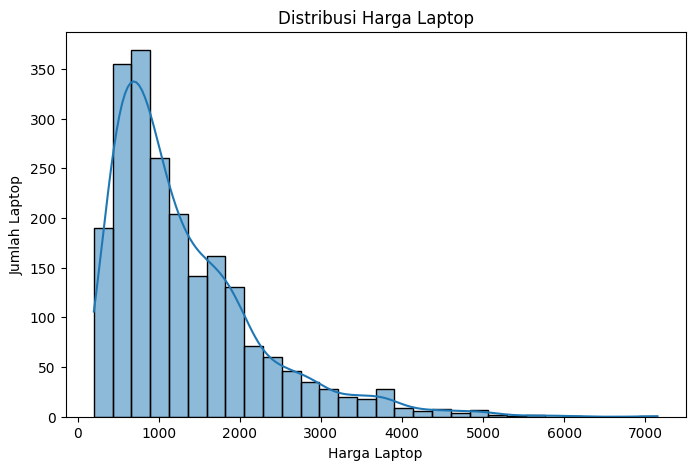

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

# Membuat histogram distribusi harga laptop
plt.figure(figsize=(8, 5)) #plt.figure(figsize=(8, 5)): menentukan ukuran grafik.
sns.histplot(data=df, x="Final Price", bins=30, kde=True) #sns.histplot(...): menampilkan distribusi harga laptop. bins=30: membagi rentang harga menjadi 30 kelompok. kde=True: menambahkan garis perkiraan bentuk distribusi.

plt.title("Distribusi Harga Laptop") #plt.title() dan plt.xlabel() / plt.ylabel(): memberi judul serta label grafik.
plt.xlabel("Harga Laptop")
plt.ylabel("Jumlah Laptop")
plt.show() #plt.show(): menampilkan grafik

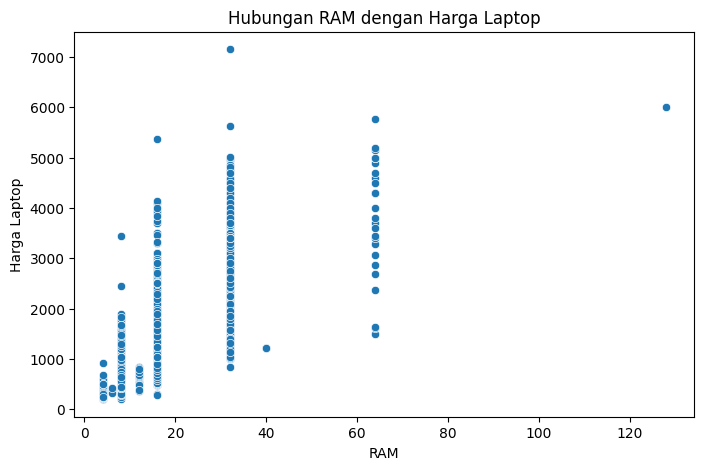

In [32]:
plt.figure(figsize=(8, 5))

sns.scatterplot( #scatterplot() membuat grafik titik untuk membandingkan dua variabel numerik.
    data=df,
    x="RAM", #x="RAM" menempatkan kapasitas RAM pada sumbu horizontal.
    y="Final Price" #y="Final Price" menempatkan harga laptop pada sumbu vertikal.
)

plt.title("Hubungan RAM dengan Harga Laptop")
plt.xlabel("RAM")
plt.ylabel("Harga Laptop")
plt.show()

#Setiap titik mewakili satu laptop.

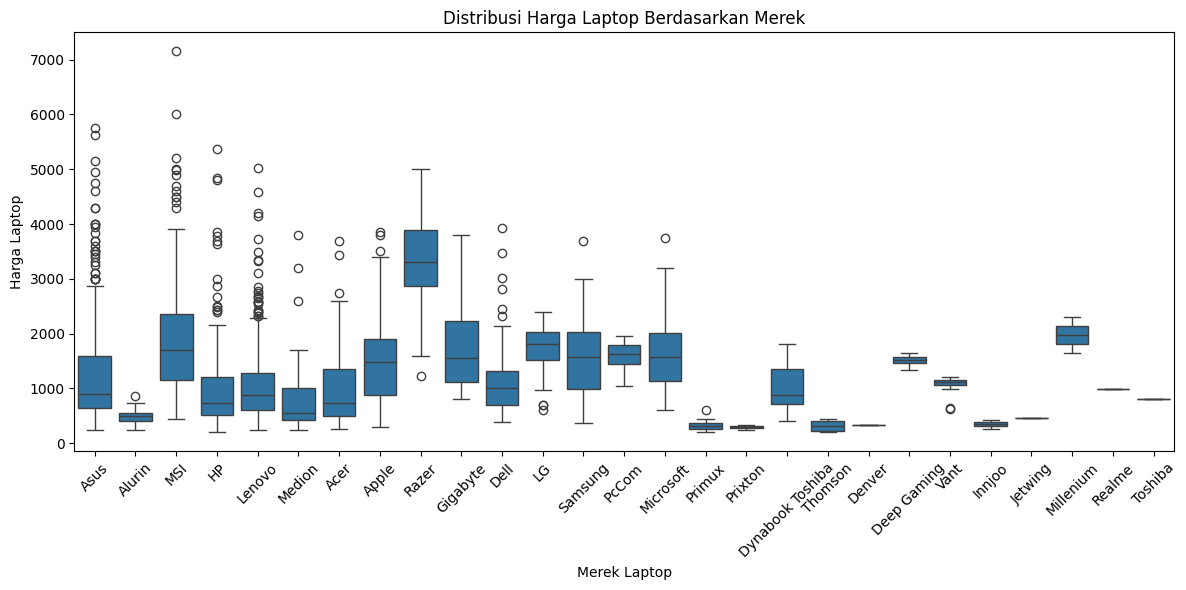

In [33]:
plt.figure(figsize=(12, 6))

sns.boxplot( #sns.boxplot() membandingkan distribusi harga antar-merek.
    data=df,
    x="Brand", #x="Brand" menentukan merek laptop pada sumbu horizontal.
    y="Final Price" #y="Final Price" menentukan harga pada sumbu vertikal.
)

plt.title("Distribusi Harga Laptop Berdasarkan Merek")
plt.xlabel("Merek Laptop")
plt.ylabel("Harga Laptop")
plt.xticks(rotation=45) #plt.xticks(rotation=45) memiringkan nama merek agar lebih mudah dibaca.
plt.tight_layout() #plt.tight_layout() mengatur tata letak supaya label tidak terpotong.
plt.show()

In [34]:
# DATA PROCESSING

In [35]:
# Menentukan fitur (X) dan target (y) X berisi informasi yang digunakan untuk memprediksi harga. y berisi harga laptop yang ingin diprediksi.
X = df.drop(
    columns=["Final Price", "Laptop", "Model"], #Final Price dikeluarkan dari X karena merupakan target yang akan diprediksi. Laptop dan Model untuk sementara dikeluarkan agar model tidak terlalu bergantung pada nama produk yang sangat spesifik. Nanti keduanya bisa dipertimbangkan kembali jika memang dibutuhkan.
    errors="ignore"
)

y = df["Final Price"]

# Melihat ukuran fitur dan target
print("Ukuran X:", X.shape) #shape menunjukkan jumlah baris dan kolom.
print("Ukuran y:", y.shape)

# Melihat kolom fitur
print("Kolom fitur:")
print(X.columns.tolist())

Ukuran X: (2160, 9)
Ukuran y: (2160,)
Kolom fitur:
['Status', 'Brand', 'CPU', 'RAM', 'Storage', 'Storage type', 'GPU', 'Screen', 'Touch']


In [36]:
# Memisahkan fitur numerik dan kategorikal
numeric_features = X.select_dtypes(
    include=["number"] #select_dtypes(include=["number"]) memilih kolom yang berisi angka, seperti RAM, Storage, dan Screen.
).columns

categorical_features = X.select_dtypes(
    include=["object", "category", "bool", "str"] #select_dtypes(include=["object", "category", "bool", "str"]) memilih kolom berupa teks atau kategori, seperti Brand, CPU, dan GPU.
).columns #.columns mengambil nama-nama kolom yang sesuai.

print("Fitur numerik:")
print(numeric_features.tolist()) #.tolist() menampilkan nama kolom dalam bentuk daftar.

print("\nFitur kategorikal:")
print(categorical_features.tolist())

Fitur numerik:
['RAM', 'Storage', 'Screen']

Fitur kategorikal:
['Status', 'Brand', 'CPU', 'Storage type', 'GPU', 'Touch']


In [37]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# 1. Preprocessing untuk fitur numerik
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# 2. Preprocessing untuk fitur kategorikal
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# 3. Menggabungkan kedua preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Preprocessing berhasil dibuat.")

Preprocessing berhasil dibuat.


In [38]:
# DATA SPLITTING

In [39]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split( #X_train dan y_train: data yang dipakai untuk melatih model. X_test dan y_test: data untuk mengevaluasi kemampuan model pada data yang tidak dipakai saat pelatihan.
    X,
    y,
    test_size=0.2, #test_size=0.2: 20% data untuk pengujian dan 80% untuk pelatihan.
    random_state=42 #random_state=42: menjaga pembagian data tetap sama ketika kode dijalankan kembali dengan dataset yang sama.
)

print("Jumlah data X_train:", X_train.shape)
print("Jumlah data X_test:", X_test.shape)
print("Jumlah data y_train:", y_train.shape)
print("Jumlah data y_test:", y_test.shape)

Jumlah data X_train: (1728, 9)
Jumlah data X_test: (432, 9)
Jumlah data y_train: (1728,)
Jumlah data y_test: (432,)


In [40]:
# MODELLING

In [41]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

# Menggabungkan preprocessing dan model
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

# Melatih model menggunakan data latih
model.fit(X_train, y_train)

print("Model berhasil dilatih.")

Model berhasil dilatih.


In [42]:
# Memprediksi harga laptop dari data uji
y_pred = model.predict(X_test)

# Membandingkan harga sebenarnya dan hasil prediksi
hasil_prediksi = pd.DataFrame({
    "Harga Sebenarnya": y_test.values,
    "Harga Prediksi": y_pred
})

print(hasil_prediksi.head(10))

   Harga Sebenarnya  Harga Prediksi
0           1123.29     1517.867024
1            201.05      321.684467
2            997.74     1527.650155
3           1016.00     1234.614852
4           2739.00     3449.787646
5           1183.68     1506.314821
6           1123.00     1286.862242
7            423.58      708.024322
8           2866.16     2466.942610
9           3399.99     3424.855418


In [43]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Menghitung nilai evaluasi model
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# Menampilkan hasil evaluasi
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 261.5954963511929
RMSE: 445.70026823745076
R2 Score: 0.7845755989254944


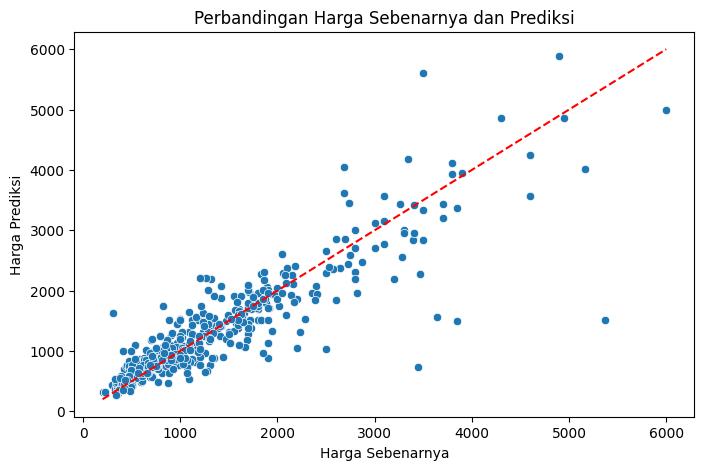

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=y_test,
    y=y_pred
)

# Garis prediksi ideal
batas_min = min(y_test.min(), y_pred.min())
batas_max = max(y_test.max(), y_pred.max())

plt.plot(
    [batas_min, batas_max],
    [batas_min, batas_max],
    "r--"
)

plt.xlabel("Harga Sebenarnya")
plt.ylabel("Harga Prediksi")
plt.title("Perbandingan Harga Sebenarnya dan Prediksi")
plt.show()